In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:

import pandas as pd


df = pd.read_csv('/content/drive/MyDrive/main project /converted.csv')
print("Shape:", df.shape)
print("\nMissing values:")
print(df.isna().sum().sort_values(ascending=False))
print("\nDuplicate job IDs:", df["job_idx"].duplicated().sum())
print("\nPower statistics:")
print(df["mean_power"].describe())
print("\nNode count statistics:")
print(df["node_count"].describe())


/tmp/ipykernel_3361/1030150186.py:4: DtypeWarning: Columns (17) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('/content/drive/MyDrive/main project /converted.csv')


Shape: (152400, 26)

Missing values:
gpu_enabled            62943
init_priority           1004
queue_time                 1
node_count                 0
date_dir                   0
submit_time                0
end_time                   0
wall_time                  0
start_time                 0
job_idx                    0
node_hour_usage            0
run_time                   0
exit_code                  0
completion_state           0
derived_exit_code          0
final_priority             0
queue                      0
job_mode                   0
peak_power                 0
mean_power                 0
user_id                    0
project_id                 0
project_prefix             0
host_list                  0
node_list                  0
interconnect_exists        0
dtype: int64

Duplicate job IDs: 0

Power statistics:
count    1.524000e+05
mean     1.148936e+05
std      6.288677e+05
min      3.010000e+02
25%      1.085000e+03
50%      3.702000e+03
75%      2.459075e+04
m

In [ ]:
print('Missing values in each column:')
print(df.isnull().sum())

print('\nSummary of mean_power:')
print(df['mean_power'].describe())

print('\nZero or negative mean_power values:')
print((df['mean_power'] <= 0).sum())

Missing values in each column:
job_idx                    0
date_dir                   0
node_count                 0
submit_time                0
start_time                 0
end_time                   0
wall_time                  0
queue_time                 1
run_time                   0
node_hour_usage            0
completion_state           0
exit_code                  0
derived_exit_code          0
init_priority           1004
final_priority             0
queue                      0
job_mode                   0
gpu_enabled            62943
peak_power                 0
mean_power                 0
user_id                    0
project_id                 0
project_prefix             0
host_list                  0
node_list                  0
interconnect_exists        0
dtype: int64

Summary of mean_power:
count    1.524000e+05
mean     1.148936e+05
std      6.288677e+05
min      3.010000e+02
25%      1.085000e+03
50%      3.702000e+03
75%      2.459075e+04
max      2.201389e+07
Na

In [ ]:
# Convert submit_time to datetime first
df['submit_time'] = pd.to_datetime(df['submit_time'])

print('Earliest submission:', df['submit_time'].min())
print('Latest submission:', df['submit_time'].max())

print('\nNumber of jobs submitted in each month:')
print(df['submit_time'].dt.strftime('%Y-%m').value_counts().sort_index())

Earliest submission: 2024-01-14 17:42:00+00:00
Latest submission: 2026-01-01 04:47:11+00:00

Number of jobs submitted in each month:
submit_time
2024-01     6920
2024-02     6688
2024-03    10712
2024-04     4182
2024-05     8444
2024-06     6071
2024-07     4566
2024-08     6153
2024-09     7012
2024-10     3896
2024-11     5602
2024-12     5977
2025-01     6952
2025-02     6477
2025-03    10219
2025-04     9213
2025-05     4760
2025-06     3794
2025-07     5954
2025-08     4678
2025-09     3323
2025-10     6792
2025-11     8793
2025-12     5147
2026-01       75
Name: count, dtype: int64


In [ ]:
import pyarrow.parquet as pq

schema = pq.read_schema(
    '/content/drive/MyDrive/main project /frontier-completed-job-info (1).parquet')
print(schema)

job_idx: large_string
date_dir: large_string
node_count: int64
submit_time: timestamp[ms, tz=UTC]
start_time: timestamp[ms, tz=UTC]
end_time: timestamp[ms, tz=UTC]
wall_time: int64
queue_time: int64
run_time: int64
node_hour_usage: double
completion_state: large_string
exit_code: large_string
derived_exit_code: large_string
init_priority: int64
final_priority: int64
queue: large_string
job_mode: large_string
gpu_enabled: large_string
peak_power: double
mean_power: double
user_id: large_string
project_id: large_string
project_prefix: large_string
host_list: large_list<element: large_string>
  child 0, element: large_string
node_list: large_list<element: large_string>
  child 0, element: large_string
interconnect_exists: large_string


In [ ]:
df.sort_values('submit_time').tail(10)[['submit_time', 'start_time', 'end_time']]

,submit_time,start_time,end_time
152266,2026-01-01 02:54:57+00:00,2026-01-01 02:55:26+00:00,2026-01-01 03:00:34+00:00
152396,2026-01-01 03:14:14+00:00,2026-01-01 03:14:50+00:00,2026-01-01 04:58:26+00:00
152282,2026-01-01 03:26:49+00:00,2026-01-01 03:27:09+00:00,2026-01-01 03:31:33+00:00
152287,2026-01-01 03:36:41+00:00,2026-01-01 03:36:50+00:00,2026-01-01 03:47:07+00:00
152286,2026-01-01 03:41:14+00:00,2026-01-01 03:41:59+00:00,2026-01-01 03:46:52+00:00
152297,2026-01-01 03:54:56+00:00,2026-01-01 03:55:34+00:00,2026-01-01 04:35:54+00:00
152362,2026-01-01 04:05:28+00:00,2026-01-01 04:05:55+00:00,2026-01-01 04:46:24+00:00
152305,2026-01-01 04:08:00+00:00,2026-01-01 04:08:30+00:00,2026-01-01 04:45:00+00:00
152298,2026-01-01 04:15:41+00:00,2026-01-01 04:16:27+00:00,2026-01-01 04:37:20+00:00
152376,2026-01-01 04:47:11+00:00,2026-01-01 04:47:26+00:00,2026-01-01 04:49:48+00:00


In [ ]:
time_columns = ["submit_time", "start_time", "end_time"]

for column in time_columns:
    df[column] = pd.to_datetime(df[column], utc=True, errors="coerce")

print("Missing or unreadable timestamps:")
print(df[time_columns].isna().sum())

print("\nTimestamp data types:")
print(df[time_columns].dtypes)

Missing or unreadable timestamps:
submit_time    0
start_time     0
end_time       0
dtype: int64

Timestamp data types:
submit_time    datetime64[ns, UTC]
start_time     datetime64[ns, UTC]
end_time       datetime64[ns, UTC]
dtype: object


In [ ]:
start_before_submit = df["start_time"] < df["submit_time"]
end_before_start = df["end_time"] < df["start_time"]

print("Jobs starting before submission:", start_before_submit.sum())
print("Jobs ending before starting:", end_before_start.sum())

print("\nJobs with zero recorded duration:",
      (df["end_time"] == df["start_time"]).sum())

Jobs starting before submission: 0
Jobs ending before starting: 0

Jobs with zero recorded duration: 0


We performed timestamp validation to ensure the chronological consistency of computing jobs. We checked whether any jobs started before submission, ended before starting, or had zero recorded duration. All three checks returned zero, indicating that the dataset passed these basic timestamp consistency tests.

In [ ]:
duration_seconds = (
    df["end_time"] - df["start_time"]
).dt.total_seconds()

runtime_difference = df["run_time"] - duration_seconds

print("Difference: recorded run_time minus calculated duration")
print(runtime_difference.describe())

print("\nJobs with a difference greater than 1 second:",
      (runtime_difference.abs() > 1).sum())

Difference: recorded run_time minus calculated duration
count    152400.0
mean          0.0
std           0.0
min           0.0
25%           0.0
50%           0.0
75%           0.0
max           0.0
dtype: float64

Jobs with a difference greater than 1 second: 0


We performed runtime consistency validation by calculating the duration of each job from its start and end timestamps and comparing it with the recorded run_time column. We found that all 152,400 jobs had matching values, indicating that the recorded runtimes are internally consistent with the timestamps.

In [ ]:
waiting_seconds = (
    df["start_time"] - df["submit_time"]
).dt.total_seconds()

queue_difference = df["queue_time"] - waiting_seconds

print("Missing recorded queue_time values:",
      df["queue_time"].isna().sum())

print("\nDifference: recorded queue_time minus calculated waiting time")
print(queue_difference.describe())

print("\nJobs with a difference greater than 1 second:",
      (queue_difference.abs() > 1).sum())

Missing recorded queue_time values: 1

Difference: recorded queue_time minus calculated waiting time
count    1.523990e+05
mean    -1.189137e+04
std      1.072852e+05
min     -8.890897e+06
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      0.000000e+00
dtype: float64

Jobs with a difference greater than 1 second: 15901


In [ ]:
largest_differences = queue_difference.abs().nlargest(5).index

queue_review = df.loc[
    largest_differences,
    ["job_idx", "submit_time", "start_time", "queue_time"]
].copy()

queue_review["elapsed_wait_seconds"] = waiting_seconds.loc[largest_differences]
queue_review["difference_seconds"] = queue_difference.loc[largest_differences]

display(queue_review)

,job_idx,submit_time,start_time,queue_time,elapsed_wait_seconds,difference_seconds
122313,122314,2025-04-06 03:55:02+00:00,2025-07-27 02:21:25+00:00,780286.0,9671183.0,-8890897.0
130228,130229,2025-06-27 15:23:12+00:00,2025-09-09 20:47:38+00:00,108557.0,6413066.0,-6304509.0
128610,128611,2025-06-27 15:23:12+00:00,2025-09-08 08:47:04+00:00,50139.0,6283432.0,-6233293.0
84378,84379,2024-12-15 03:09:43+00:00,2025-02-10 08:54:23+00:00,0.0,4945480.0,-4945480.0
84376,84377,2024-12-15 03:09:43+00:00,2025-02-10 08:50:10+00:00,3.0,4945227.0,-4945224.0


### Checking Jobs with the Largest Queue Time Differences

This code finds the **5 jobs with the biggest differences** between the recorded queue waiting time (`queue_time`) and the waiting time calculated from timestamps.

**What the code does:**

1. `queue_difference.abs().nlargest(5)` finds the 5 largest differences, ignoring whether they are positive or negative.
2. `.index` gets the row indexes of those 5 jobs.
3. `df.loc[]` selects those jobs and displays their job ID, submission time, start time, and recorded queue time.
4. `.copy()` creates a separate copy of the selected data.
5. `elapsed_wait_seconds` adds the waiting time calculated from `start_time - submit_time`.
6. `difference_seconds` adds the difference between the recorded and calculated waiting times.
7. `display(queue_review)` shows the results as a table.

**Why are we doing this?**

We want to investigate jobs where the recorded queue time does not match the waiting time calculated from the timestamps.

This helps us identify possible data inconsistencies and understand whether the queue time measurements are reliable.

**Note:** This code only identifies and displays the 5 largest differences. It does not remove or modify any jobs.

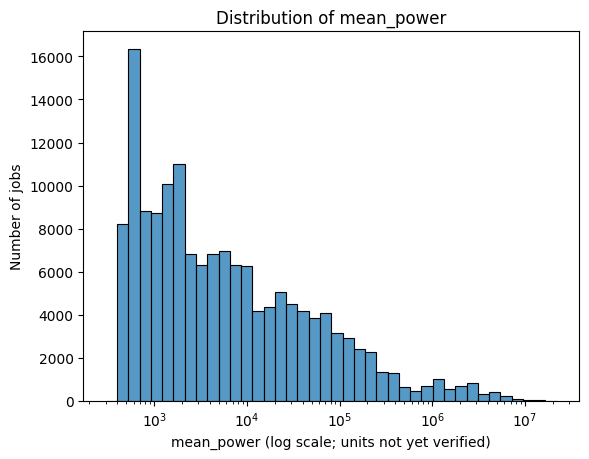

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(df['mean_power'], bins=40, log_scale=True)
plt.title('Distribution of mean_power')
plt.xlabel('mean_power (log scale; units not yet verified)')
plt.ylabel('Number of jobs')
plt.show()

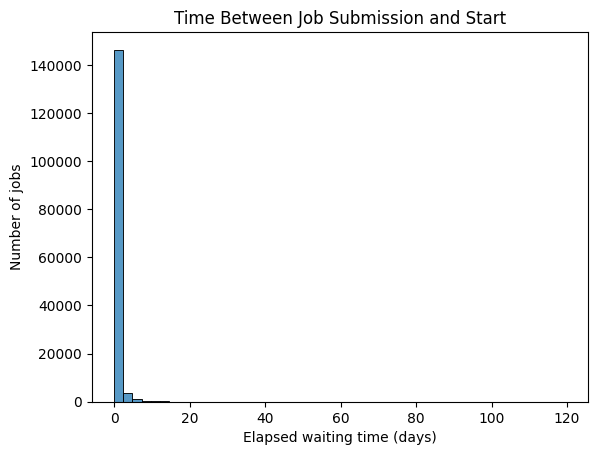

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

waiting_days = (
    df["start_time"] - df["submit_time"]
).dt.total_seconds() / 86400

sns.histplot(waiting_days, bins=50)

plt.title("Time Between Job Submission and Start")
plt.xlabel("Elapsed waiting time (days)")
plt.ylabel("Number of jobs")
plt.show()

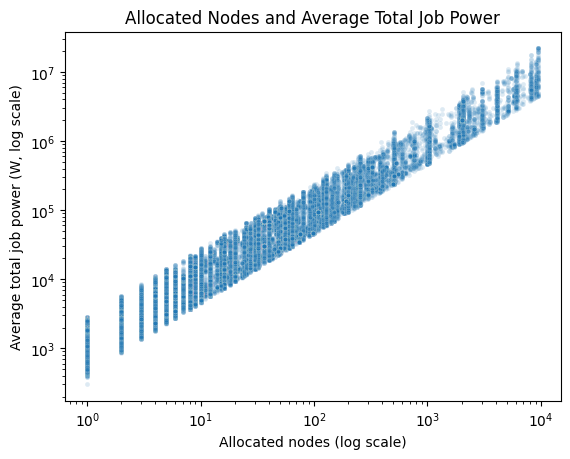

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.scatterplot(
    data=df,
    x="node_count",
    y="mean_power",
    alpha=0.15,
    s=12
)

plt.xscale("log")
plt.yscale("log")
plt.title("Allocated Nodes and Average Total Job Power")
plt.xlabel("Allocated nodes (log scale)")
plt.ylabel("Average total job power (W, log scale)")
plt.show()

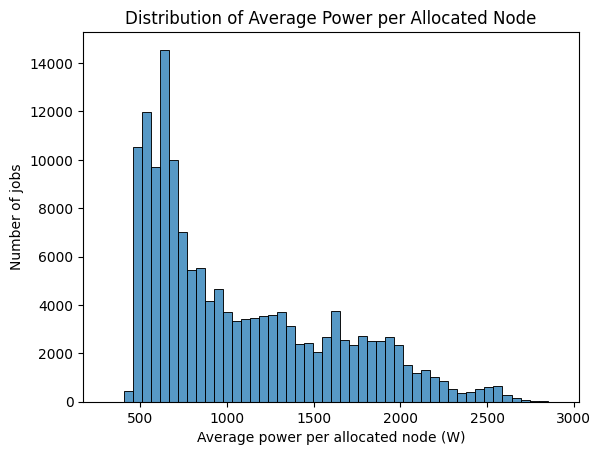

In [ ]:
power_per_node = df["mean_power"] / df["node_count"]

sns.histplot(power_per_node, bins=50)

plt.title("Distribution of Average Power per Allocated Node")
plt.xlabel("Average power per allocated node (W)")
plt.ylabel("Number of jobs")
plt.show()

queue
batch-normal          129704
batch-debug            17835
extended-normal         3192
batch-spi-normal        1083
batch-spi-debug          296
extended-debug           284
batch-hackathon            4
extended-hackathon         2
Name: count, dtype: int64


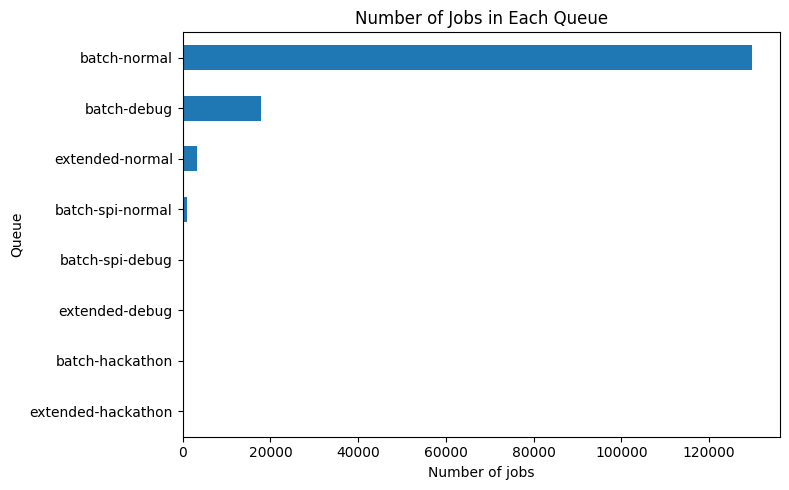

In [ ]:
queue_counts = df["queue"].fillna("Missing").value_counts()

print(queue_counts)

queue_counts.sort_values().plot(
    kind="barh",
    figsize=(8, 5)
)

plt.title("Number of Jobs in Each Queue")
plt.xlabel("Number of jobs")
plt.ylabel("Queue")
plt.tight_layout()
plt.show()

Total numerical columns: 10
Numerical columns: ['job_idx', 'node_count', 'wall_time', 'queue_time', 'run_time', 'node_hour_usage', 'init_priority', 'final_priority', 'peak_power', 'mean_power']


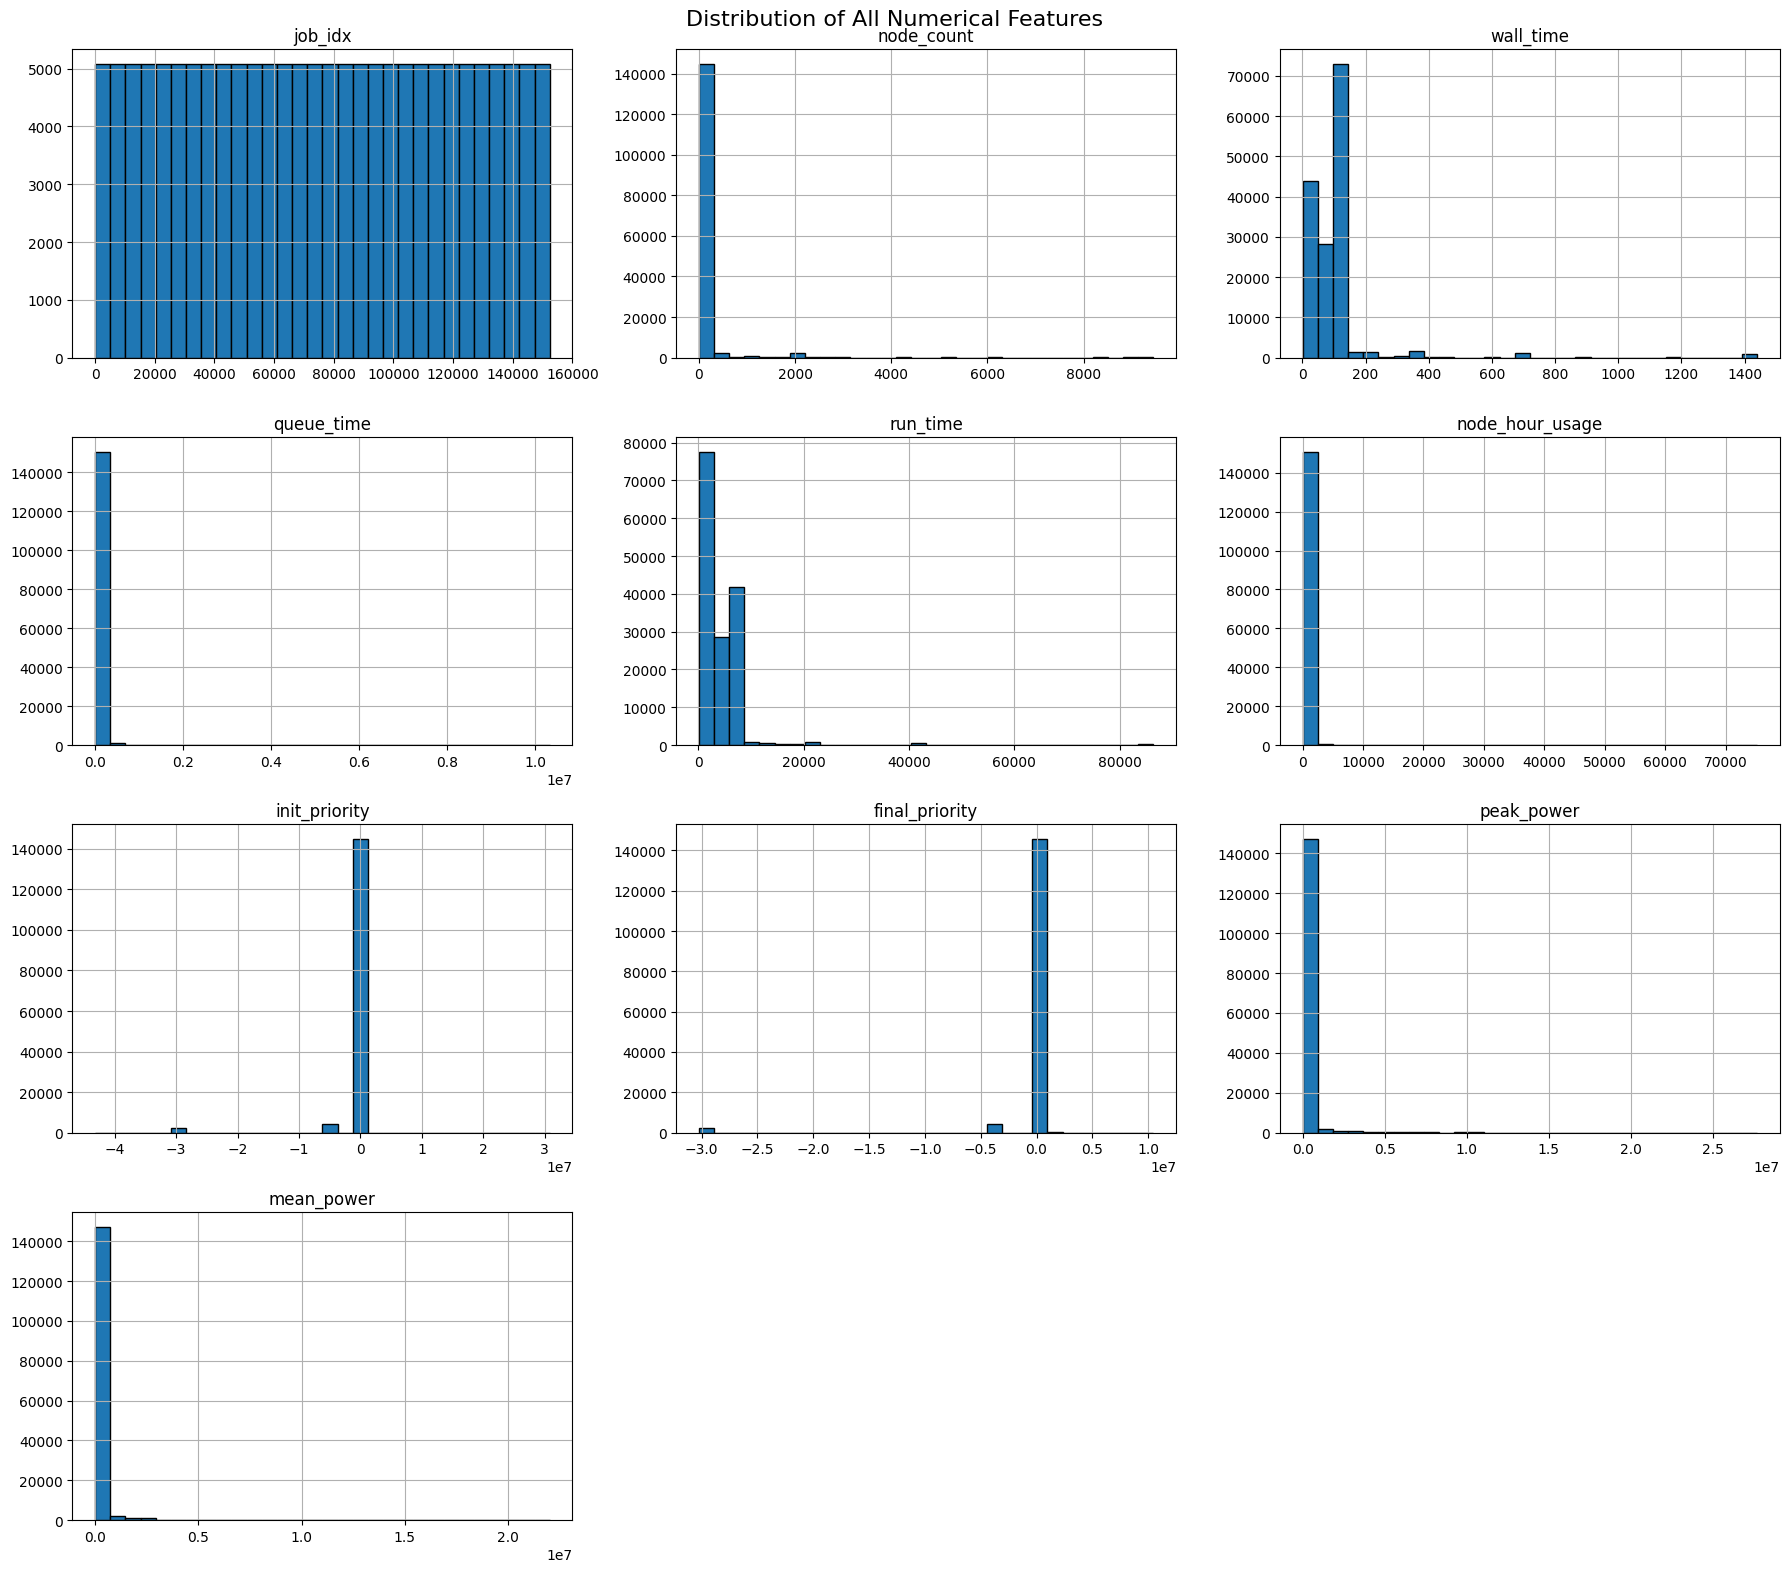

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Select all numerical columns
numerical_columns = df.select_dtypes(include='number').columns

print("Total numerical columns:", len(numerical_columns))
print("Numerical columns:", numerical_columns.tolist())

# Plot histograms
df[numerical_columns].hist(
    figsize=(18, 16),
    bins=30,
    edgecolor='black'
)

plt.suptitle("Distribution of All Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
# Runtime values are in seconds
print("Runtime summary:")
print(df["run_time"].describe())

print("\nRuntime percentiles:")
print(df["run_time"].quantile([0.50, 0.90, 0.95, 0.99]))

print("\nValues to investigate:")
print("Missing:", df["run_time"].isna().sum())
print("Negative:", (df["run_time"] < 0).sum())
print("Zero:", (df["run_time"] == 0).sum())

Runtime summary:
count    152400.000000
mean       4022.559298
std        6115.907768
min          70.000000
25%         682.000000
50%        2764.000000
75%        6500.000000
max       86429.000000
Name: run_time, dtype: float64

Runtime percentiles:
0.50     2764.00
0.90     7217.00
0.95     7226.00
0.99    24702.06
Name: run_time, dtype: float64

Values to investigate:
Missing: 0
Negative: 0
Zero: 0


### **Job Duration Metrics Summary**

* **Median:** 2,764 seconds (~46 minutes)  
  *Half the jobs finish within this time.*
* **Mean:** 4,023 seconds (~67 minutes)  
  *Longer jobs pull the average above the median.*
* **99th Percentile:** 24,702 seconds (~6.9 hours)  
* **Maximum:** 86,429 seconds (~24 hours)  
  *This deserves inspection, but is not automatically an error.*

In [ ]:
# Check the likely conversion from minutes to seconds
wall_time_seconds = df["wall_time"] * 60
runtime_difference = df["run_time"] - wall_time_seconds


print(runtime_difference.describe())

print("\nJobs exceeding the converted limit by more than 60 seconds:")
print((runtime_difference > 60).sum())

print("\nMedian runtime for jobs requesting 120 minutes:")#The code selects jobs that requested 120 minutes, then finds their median actual runtime.
print(df.loc[df["wall_time"] == 120, "run_time"].median())

count    152400.000000
mean      -1951.550938
std        4933.768837
min      -86329.000000
25%       -2407.000000
50%        -673.000000
75%           6.000000
max          70.000000
dtype: float64

Jobs exceeding the converted limit by more than 60 seconds:
3

Median runtime for jobs requesting 120 minutes:
6138.0


we find that that the wall-time in min and run-time in second

In [ ]:
# Original wall_time is in minutes; create a seconds version
df["wall_time_seconds"] = df["wall_time"] * 60

print(df[["wall_time", "wall_time_seconds", "run_time"]].head())

   wall_time  wall_time_seconds  run_time
0        105               6300      5317
1         30               1800      1506
2         60               3600      3424
3        120               7200      7201
4         25               1500      1112


In [ ]:
# Actual runtime divided by requested time, both in seconds
df["runtime_ratio"] = df["run_time"] / df["wall_time_seconds"]


print(df[["run_time", "wall_time_seconds", "runtime_ratio"]].head())

   run_time  wall_time_seconds  runtime_ratio
0      5317               6300       0.843968
1      1506               1800       0.836667
2      3424               3600       0.951111
3      7201               7200       1.000139
4      1112               1500       0.741333


This output tells us how much of the requested time jobs actually use. It helps us understand how useful the requested time is for predicting runtime.

For your first job:

5,317 ÷ 6,300 = 0.844 → it used about 84% of its requested time.

In [ ]:
# Show the 10 longest-running jobs
print(
    df.nlargest(10, "run_time")[
        ["node_count", "wall_time_seconds", "run_time", "runtime_ratio"]
    ]
)

        node_count  wall_time_seconds  run_time  runtime_ratio
91596            9              86400     86429       1.000336
111431          17              86400     86429       1.000336
133892          48              86400     86429       1.000336
135810           1              86400     86429       1.000336
89059           32              86400     86428       1.000324
101434          24              86400     86428       1.000324
101435           1              86400     86428       1.000324
116982          50              86400     86428       1.000324
129709          40              86400     86428       1.000324
136433          28              86400     86428       1.000324


In [ ]:
# Check timestamp formats and view a few records
print(df[["submit_time", "end_time"]].dtypes)

print("\nFirst five timestamp records:")
print(df[["submit_time", "end_time"]].head())

submit_time    datetime64[ns, UTC]
end_time       datetime64[ns, UTC]
dtype: object

First five timestamp records:
                submit_time                  end_time
0 2024-01-15 13:23:57+00:00 2024-01-17 05:02:27+00:00
1 2024-01-17 04:39:48+00:00 2024-01-17 05:05:24+00:00
2 2024-01-17 04:04:02+00:00 2024-01-17 05:06:39+00:00
3 2024-01-17 03:09:54+00:00 2024-01-17 05:10:19+00:00
4 2024-01-17 00:08:01+00:00 2024-01-17 05:16:56+00:00


In [ ]:
# Use UTC cutoffs to match the timestamp columns
train_cutoff = pd.Timestamp("2025-04-01", tz="UTC")
test_cutoff = pd.Timestamp("2025-07-01", tz="UTC")

train_df = df[
    (df["submit_time"] < train_cutoff) &
    (df["end_time"] < train_cutoff)
].copy()

print("Training jobs:", len(train_df))
print("Earliest submission:", train_df["submit_time"].min())
print("Latest submission:", train_df["submit_time"].max())
print("Latest completion:", train_df["end_time"].max())

Training jobs: 99552
Earliest submission: 2024-01-14 17:42:00+00:00
Latest submission: 2025-03-31 23:54:44+00:00
Latest completion: 2025-03-31 23:59:59+00:00


### Time-based data split

Jobs are grouped by submission date, from oldest to newest.

```text
                  April 1, 2025           July 1, 2025
                        │                       │
   TRAINING             │     VALIDATION        │       TEST
◀───────────────────────┼───────────────────────┼──────────────────▶
   Before April 1       │  April 1 – June 30    │  July 1 onward
                        │                       │
   Learn patterns       │  Compare and tune     │  Final evaluation
```

**Training rule:** A job must be submitted AND completed before April 1.
A job submitted in March but completed in April cannot be used for training
at the April 1 cutoff.

**Validation rule:** Use jobs submitted from April 1 up to July 1, with
outcomes available before July 1, to choose the model.

**Test rule:** Use jobs submitted from July 1 onward for the final evaluation.
This period was examined in earlier experiments, so it is not a completely
untouched test set.

In [ ]:
# Submitted during April–June and completed before July 1
val_df = df[
    (df["submit_time"] >= train_cutoff) &
    (df["submit_time"] < test_cutoff) &
    (df["end_time"] < test_cutoff)
].copy()

print("Validation jobs:", len(val_df))
print("Earliest submission:", val_df["submit_time"].min())
print("Latest submission:", val_df["submit_time"].max())
print("Latest completion:", val_df["end_time"].max())

Validation jobs: 17717
Earliest submission: 2025-04-01 00:02:16+00:00
Latest submission: 2025-06-30 03:22:27+00:00
Latest completion: 2025-06-30 03:55:31+00:00


                    April 1, 2025           July 1, 2025
                          │                       │
      TRAINING            │     VALIDATION        │       TEST
◀─────────────────────────┼───────────────────────┼────────────────▶
      99,552 jobs         │     Creating now      │     Next step
                          │                       │
 Submitted and completed  │ Submitted April–June  │ Submitted from
 before April 1           │ Completed before     │ July 1 onward
                          │ July 1                │

In [ ]:
# Jobs submitted from July 1 onward
test_df = df[df["submit_time"] >= test_cutoff].copy()

print("Test jobs:", len(test_df))
print("Earliest submission:", test_df["submit_time"].min())
print("Latest submission:", test_df["submit_time"].max())

Test jobs: 34762
Earliest submission: 2025-07-02 03:09:44+00:00
Latest submission: 2026-01-01 04:47:11+00:00


                    April 1, 2025           July 1, 2025
                          │                       │
      TRAINING            │     VALIDATION        │       TEST
◀─────────────────────────┼───────────────────────┼────────────────▶
      99,552 jobs         │     17,717 jobs       │   Creating now
                          │                       │
      Learn patterns      │   Compare models      │   Final score

                    April 1, 2025           July 1, 2025
                          │                       │
      TRAINING            │     VALIDATION        │       TEST
◀─────────────────────────┼───────────────────────┼────────────────▶
      99,552 jobs         │     17,717 jobs       │   34,762 jobs
                          │                       │
      Learn patterns      │   Compare models      │   Final score

In [ ]:
# Submitted before April 1, but not completed before April 1
train_boundary = (
    (df["submit_time"] < train_cutoff) &
    (df["end_time"] >= train_cutoff)
)

# Submitted during April–June, but not completed before July 1
val_boundary = (
    (df["submit_time"] >= train_cutoff) &
    (df["submit_time"] < test_cutoff) &
    (df["end_time"] >= test_cutoff)
)

print("Jobs crossing the training cutoff:", train_boundary.sum())
print("Jobs crossing the validation cutoff:", val_boundary.sum())
print("Total boundary jobs:", train_boundary.sum() + val_boundary.sum())

Jobs crossing the training cutoff: 319
Jobs crossing the validation cutoff: 50
Total boundary jobs: 369


In [ ]:
# Show only columns containing missing values in training
missing = train_df.isna().sum()

print("Missing values in training:")
print(missing[missing > 0].sort_values(ascending=False))

Missing values in training:
gpu_enabled      62943
init_priority     1004
queue_time           1
dtype: int64


In [ ]:
train_df["gpu_enabled"] = train_df["gpu_enabled"].astype("string").fillna("Unknown")
val_df["gpu_enabled"] = val_df["gpu_enabled"].astype("string").fillna("Unknown")
test_df["gpu_enabled"] = test_df["gpu_enabled"].astype("string").fillna("Unknown")

print(train_df["gpu_enabled"].value_counts(dropna=False))
print("\nData type:", train_df["gpu_enabled"].dtype)

gpu_enabled
Unknown    62943
True       23615
False      12994
Name: count, dtype: Int64

Data type: string


In [ ]:
# Learn the replacement value from training data only
priority_median = train_df["init_priority"].median()

train_df["init_priority"] = train_df["init_priority"].fillna(priority_median)
val_df["init_priority"] = val_df["init_priority"].fillna(priority_median)
test_df["init_priority"] = test_df["init_priority"].fillna(priority_median)

print("Training median used:", priority_median)

print("\nRemaining missing priorities:")
print("Training:", train_df["init_priority"].isna().sum())
print("Validation:", val_df["init_priority"].isna().sum())
print("Test:", test_df["init_priority"].isna().sum())

Training median used: 172800.0

Remaining missing priorities:
Training: 0
Validation: 0
Test: 0


In [ ]:
priority_median = train_df["init_priority"].median()

train_df["init_priority"] = train_df["init_priority"].fillna(priority_median)
val_df["init_priority"] = val_df["init_priority"].fillna(priority_median)
test_df["init_priority"] = test_df["init_priority"].fillna(priority_median)

print("Training median used:", priority_median)
print("Missing in training:", train_df["init_priority"].isna().sum())
print("Missing in validation:", val_df["init_priority"].isna().sum())
print("Missing in test:", test_df["init_priority"].isna().sum())

Training median used: 172800.0
Missing in training: 0
Missing in validation: 0
Missing in test: 0


In [ ]:
train_df.columns.tolist()

['job_idx',
 'date_dir',
 'node_count',
 'submit_time',
 'start_time',
 'end_time',
 'wall_time',
 'queue_time',
 'run_time',
 'node_hour_usage',
 'completion_state',
 'exit_code',
 'derived_exit_code',
 'init_priority',
 'final_priority',
 'queue',
 'job_mode',
 'gpu_enabled',
 'peak_power',
 'mean_power',
 'user_id',
 'project_id',
 'project_prefix',
 'host_list',
 'node_list',
 'interconnect_exists',
 'wall_time_seconds',
 'runtime_ratio']

In [ ]:
print("Columns available in training:")
print(train_df.columns.tolist())

Columns available in training:
['job_idx', 'date_dir', 'node_count', 'submit_time', 'start_time', 'end_time', 'wall_time', 'queue_time', 'run_time', 'node_hour_usage', 'completion_state', 'exit_code', 'derived_exit_code', 'init_priority', 'final_priority', 'queue', 'job_mode', 'gpu_enabled', 'peak_power', 'mean_power', 'user_id', 'project_id', 'project_prefix', 'host_list', 'node_list', 'interconnect_exists', 'wall_time_seconds', 'runtime_ratio']


In [ ]:
feature_columns = [
    "node_count",
    "wall_time_seconds",
    "init_priority",

    "queue",
    "job_mode",
    "gpu_enabled",
    "project_prefix"
]

print("Missing values in selected training inputs:")
print(train_df[feature_columns].isna().sum())

print("Starting model inputs:")
print(feature_columns)
print("\nNumber of inputs:", len(feature_columns))

Missing values in selected training inputs:
node_count           0
wall_time_seconds    0
init_priority        0
queue                0
job_mode             0
gpu_enabled          0
project_prefix       0
dtype: int64
Starting model inputs:
['node_count', 'wall_time_seconds', 'init_priority', 'queue', 'job_mode', 'gpu_enabled', 'project_prefix']

Number of inputs: 7


In [ ]:
# Simple baseline: predict 75% of the requested time
val_baseline = 0.75 * val_df["wall_time_seconds"]

baseline_mae = (val_df["run_time"] - val_baseline).abs().mean()

print("Validation baseline MAE (seconds):", round(baseline_mae, 2))
print("Validation baseline MAE (minutes):", round(baseline_mae / 60, 2))

Validation baseline MAE (seconds): 1716.58
Validation baseline MAE (minutes): 28.61


In [ ]:
# Inputs available when a job is submitted
X_train = train_df[feature_columns].copy()
X_val = val_df[feature_columns].copy()

# Actual runtime: the answer we want to predict
y_train = train_df["run_time"].copy()
y_val = val_df["run_time"].copy()

print("Training inputs:", X_train.shape)
print("Validation inputs:", X_val.shape)

Training inputs: (99552, 7)
Validation inputs: (17717, 7)


### Dataset split and model inputs

We split the original dataset chronologically:

```text
Original dataset: 152,400 jobs
│
├── Training: 99,552 jobs
│   Submitted and completed before April 1, 2025
│   │
│   ├── X_train: 8 selected input features
│   └── y_train: actual runtime in seconds
│
├── Validation: 17,717 jobs
│   Submitted April–June; completed before July 1, 2025
│   │
│   ├── X_val: the same 8 input features
│   └── y_val: actual runtime in seconds
│
├── Test: 34,762 jobs
│   Submitted from July 1, 2025 onward
│   Reserved for final evaluation in this restarted workflow
│
└── Boundary jobs: 369
    Excluded from these sets because their outcomes were
    unavailable at the relevant cutoff; retained in the original data
```

Separating X and y does not create another time split.
X contains the information used to predict; y contains the actual answer.

### Validation baseline

A baseline is a simple prediction rule used as a reference.

Our rule predicts:
Predicted runtime = 0.75 × requested time in seconds

We applied this rule to each validation job, compared its prediction
with the actual runtime, and calculated the mean absolute error (MAE).

Validation baseline MAE: 1,716.5 seconds = 28.61 minutes.

This means the predictions differed from actual runtimes by
28.61 minutes on average, ignoring whether they were too high or too low.

We need this reference to check whether machine learning improves
on a simple rule. Models must be compared on the same validation jobs.
Lower MAE is better. Validation helps us choose models and settings;
the test set is saved for the final evaluation.

Note: the test period was examined in earlier project experiments,
so it is not a completely untouched test set.

In [ ]:
categorical_columns = [
    "queue",
    "job_mode",
    "gpu_enabled",
    "project_prefix"
]

print("Number of categories in each training column:")
print(X_train[categorical_columns].nunique())

Number of categories in each training column:
queue              6
job_mode           2
gpu_enabled        3
project_prefix    33
dtype: int64


In [ ]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

train_categories = encoder.fit_transform(X_train[categorical_columns])
val_categories = encoder.transform(X_val[categorical_columns])

print("Encoded training categories:", train_categories.shape)
print("Encoded validation categories:", val_categories.shape)

Encoded training categories: (99552, 44)
Encoded validation categories: (17717, 44)


In [ ]:
import numpy as np

numeric_columns = [
    "node_count",
    "wall_time_seconds",
    "init_priority",

]

X_train_encoded = np.column_stack([
    X_train[numeric_columns].to_numpy(),
    train_categories
])

X_val_encoded = np.column_stack([
    X_val[numeric_columns].to_numpy(),
    val_categories
])

print("Final training inputs:", X_train_encoded.shape)
print("Final validation inputs:", X_val_encoded.shape)

Final training inputs: (99552, 47)
Final validation inputs: (17717, 47)


### **Dataset Feature Matrix Assembly & Split**

#### **1. Training Set Construction**
*The same **99,552 jobs** are combined across numeric and categorical features:*

```text
  4 Numeric Columns       44 Encoded Category Columns
 ┌──────────────────┐    ┌─────────────────────────────┐
 │ Job 1: numbers   │ +  │ Job 1: category indicators  │
 │ Job 2: numbers   │ +  │ Job 2: category indicators  │
 │ ...              │    │ ...                         │
 └──────────────────┘    └─────────────────────────────┘
                            │
                  Place columns side by side
                            ▼
              X_train_encoded: 99,552 rows × 48 columns

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_encoded)
X_val_scaled = scaler.transform(X_val_encoded)

print("Scaled training inputs:", X_train_scaled.shape)
print("Scaled validation inputs:", X_val_scaled.shape)

Scaled training inputs: (99552, 47)
Scaled validation inputs: (17717, 47)


In [ ]:
print("Selected original features:")
print(X_train.columns.tolist())

print("\nNumber of original features:", X_train.shape[1])

Selected original features:
['node_count', 'wall_time_seconds', 'init_priority', 'queue', 'job_mode', 'gpu_enabled', 'project_prefix']

Number of original features: 7


In [ ]:
from sklearn.metrics import mean_absolute_error

baseline_prediction = y_train.median()

baseline_mae = mean_absolute_error(
    y_val,
    [baseline_prediction] * len(y_val)
)

print("Baseline prediction:", baseline_prediction, "seconds")
print("Baseline validation MAE:", round(baseline_mae, 2), "seconds")

Baseline prediction: 2970.0 seconds
Baseline validation MAE: 2910.27 seconds
